# Mini-Project 2: Uganda Tax Calculator

**Course:** MSCS & MSDS OOP with Python — Assignment 2 (Advent 2026)

An extensible, testable engine for computing Uganda Revenue Authority (URA)
taxes. The notebook demonstrates:

- **`Money`** — a `Decimal`-only value object for UGX with operator overloading.
- **`Tax`** — an abstract base class with a single `calculate(ctx)` contract.
- **`PAYE`** — progressive monthly bands for residents, flat rate for non-residents.
- **`NSSF`** — 5% employee / 10% employer contributions.
- **`LST`** — configurable Local Service Tax deducted before PAYE.
- **`VAT`** — standard, zero-rated, and exempt supplies with input-VAT offset.
- **`CIT`** — 30% corporate income tax on chargeable income.
- **`PayrollPipeline`** — composes the above in the documented order.

The reusable logic lives in `src/money.py`, `src/taxes.py`, and
`src/payroll.py`. Tests live in `tests/test_money.py` and
`tests/test_taxes.py`.

**Reproducibility:** runs top-to-bottom with *Kernel → Restart Kernel and
Run All Cells*. Only the config cell is editable.

---

**Data source for tax rates:** URA PAYE schedule for resident individuals,
monthly. The rates in `src/taxes.py` are the ones from the assignment brief;
verify against the current URA notice before relying on this in production.

In [1]:
# =========================================================================
# CONFIG — the only cell you may need to edit.
# =========================================================================
import os
import sys
from datetime import date
from pathlib import Path

# Sample assessment date. Used to look up the schedule vintage.
AS_OF = date(2025, 1, 1)

# Locate the repo root so `import src...` works from notebooks/.
def _find_repo_root(start: Path) -> Path:
    here = start.resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "__init__.py").exists():
            return candidate
    raise RuntimeError(f"Could not find repo root from {start}")

REPO_ROOT = _find_repo_root(Path(os.getcwd()))
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

print(f"Assessment date: {AS_OF}")
print(f"Repo root: {REPO_ROOT}")

Assessment date: 2025-01-01
Repo root: /Volumes/Data/oop-advent-2026


In [2]:
# Third-party + standard library
from decimal import Decimal

import pandas as pd
import matplotlib.pyplot as plt

# Our tax engine (importable because of the sys.path tweak above).
from src.money import Money
from src.taxes import (
    Band, BandSchedule,
    CIT, PAYE, VAT,
    TaxContext, TaxResult,
    PAYE_RESIDENT_SCHEDULE,
    SURCHARGE_THRESHOLD, SURCHARGE_RATE,
)
from src.payroll import LST, NSSF, PayrollPipeline, PayrollResult
from src.exceptions import (
    InvalidIncomeError, NoScheduleForDateError, TaxError,
)

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

print("All imports OK")

All imports OK


---

## 1. The `Money` value object

`Money` is a frozen dataclass wrapping a `Decimal` amount and a currency.
It exists to make one guarantee: **no float ever enters a tax calculation**.

Why this matters:

- `0.1 + 0.2` in Python floats equals `0.30000000000000004`.
- In a progressive tax with many multiplications and additions, float
  errors **accumulate**. A 1-shilling error per operation becomes a
  10-shilling error after ten operations. For a statutory filing, that
  is unacceptable.
- `Decimal` is exact for base-10 arithmetic. `Money` adds a rounding
  policy (`ROUND_HALF_UP` to whole UGX, matching URA practice) and
  refuses floats loudly rather than silently accepting them.

In [3]:
# -------------------------------------------------------------------------
# Money in action: construction, arithmetic, comparison, display.
# -------------------------------------------------------------------------
salary = Money(Decimal("1000000"))
allowance = Money("200000")             # str is fine; converted internally
lst = Money(Decimal("10000"))

print("salary      :", salary)
print("allowance   :", allowance)
print("lst         :", lst)
print()
print("sum         :", salary + allowance)
print("difference  :", salary - lst)
print("20% of sum  :", (salary + allowance) * Decimal("0.20"))
print()
print("salary < sum:", salary < (salary + allowance))
print("salary <= salary:", salary <= salary)
print("salary == Money(1_000_000):", salary == Money(Decimal("1000000")))
print()
print("repr        :", repr(salary))
print("str         :", str(salary))

salary      : 1,000,000 UGX
allowance   : 200,000 UGX
lst         : 10,000 UGX

sum         : 1,200,000 UGX
difference  : 990,000 UGX
20% of sum  : 240,000 UGX

salary < sum: True
salary <= salary: True
salary == Money(1_000_000): True

repr        : Money(1000000 UGX)
str         : 1,000,000 UGX


In [4]:
# -------------------------------------------------------------------------
# The killer feature: Money refuses floats. This is what makes the
# tax engine safe by construction.
# -------------------------------------------------------------------------
print("Attempting Money.of(100.5)  (a float):")
try:
    Money.of(100.5)
except TypeError as e:
    print(f"  → {type(e).__name__}: {e}")

print()
print("Attempting Money(1000) * 0.30  (float factor):")
try:
    Money(Decimal("1000")) * 0.30
except TypeError as e:
    print(f"  → {type(e).__name__}: {e}")

print()
print("The safe alternative: Money(1000) * Decimal('0.30')")
print(f"  → {Money(Decimal('1000')) * Decimal('0.30')}")

print()
print("Show the float trap directly:")
print(f"  0.1 + 0.2                    = {0.1 + 0.2}")
print(f"  Decimal('0.1') + Decimal('0.2') = {Decimal('0.1') + Decimal('0.2')}")

Attempting Money.of(100.5)  (a float):
  → TypeError: Money.of() refuses floats — pass Decimal, int, or str instead

Attempting Money(1000) * 0.30  (float factor):
  → TypeError: Money * float is unsafe — use Decimal or str for the factor

The safe alternative: Money(1000) * Decimal('0.30')
  → 300 UGX

Show the float trap directly:
  0.1 + 0.2                    = 0.30000000000000004
  Decimal('0.1') + Decimal('0.2') = 0.3


---

## 2. PAYE — Pay As You Earn

PAYE for resident individuals follows a **progressive** schedule. Each
band's marginal rate applies only to the income that falls inside that
band. The schedule is data (`BandSchedule`), not code — adding next year's
rates means adding a new instance, not editing a branch.

The current schedule (from the assignment brief):

| Band | Monthly income (UGX) | Tax |
|---|---|---|
| 1 | up to 335,000 | Nil |
| 2 | 335,001 – 410,000 | 20% of excess over 335,000 |
| 3 | 410,001 – 485,000 | 15,000 + 25% of excess over 410,000 |
| 4 | 485,001 – 10,000,000 | 33,750 + 30% of excess over 485,000 |
| 5 | above 10,000,000 | Band 4 plus 10% surcharge on excess over 10,000,000 |

**Non-resident schedule:** flat 30% on chargeable income (see the
`PAYE.calculate` docstring in `src/taxes.py`). The assignment requires
this to be supported; verify the exact non-resident bands against the
current URA notice before production use.

In [5]:
# -------------------------------------------------------------------------
# Exact boundary values — the assignment explicitly lists these.
# -------------------------------------------------------------------------
paye = PAYE()

boundaries = [
    ("0",          "0"),
    ("335000",     "0"),         # top of Nil band
    ("335001",     "0"),         # 20% × 1 = 0.20 → rounds to 0
    ("410000",     "15000"),     # 20% × 75,000
    ("410001",     "15000"),     # +25% × 1 = 0.25 → rounds to 0
    ("485000",     "33750"),     # 15,000 + 25% × 75,000
    ("485001",     "33750"),     # +30% × 1 = 0.30 → rounds to 0
    ("1000000",    "188250"),    # 33,750 + 30% × 515,000
    ("10000000",   "2888250"),   # 33,750 + 30% × 9,515,000
    ("10000001",   "2888250"),   # +10% × 1 → rounds to 0
    ("10000100",   "2888260"),   # +10% × 100 = 10 (surcharge visible)
]

rows = []
for income_str, expected_str in boundaries:
    result = paye.calculate(
        TaxContext(gross=Money(Decimal(income_str)), as_of=AS_OF)
    )
    actual = result.tax.amount
    expected = Decimal(expected_str)
    rows.append({
        "Gross (UGX)": int(income_str),
        "Expected tax": int(expected),
        "Actual tax": int(actual),
        "Match": "✅" if actual == expected else "❌",
    })

df_boundaries = pd.DataFrame(rows)
display(df_boundaries.style.format({
    "Gross (UGX)": "{:,}",
    "Expected tax": "{:,}",
    "Actual tax": "{:,}",
}))

,Gross (UGX),Expected tax,Actual tax,Match
0,0,0,0,✅
1,"335,000",0,0,✅
2,"335,001",0,0,✅
3,"410,000","15,000","15,000",✅
4,"410,001","15,000","15,000",✅
5,"485,000","33,750","33,750",✅
6,"485,001","33,750","33,750",✅
7,"1,000,000","188,250","188,250",✅
8,"10,000,000","2,888,250","2,888,250",✅
9,"10,000,001","2,888,250","2,888,250",✅


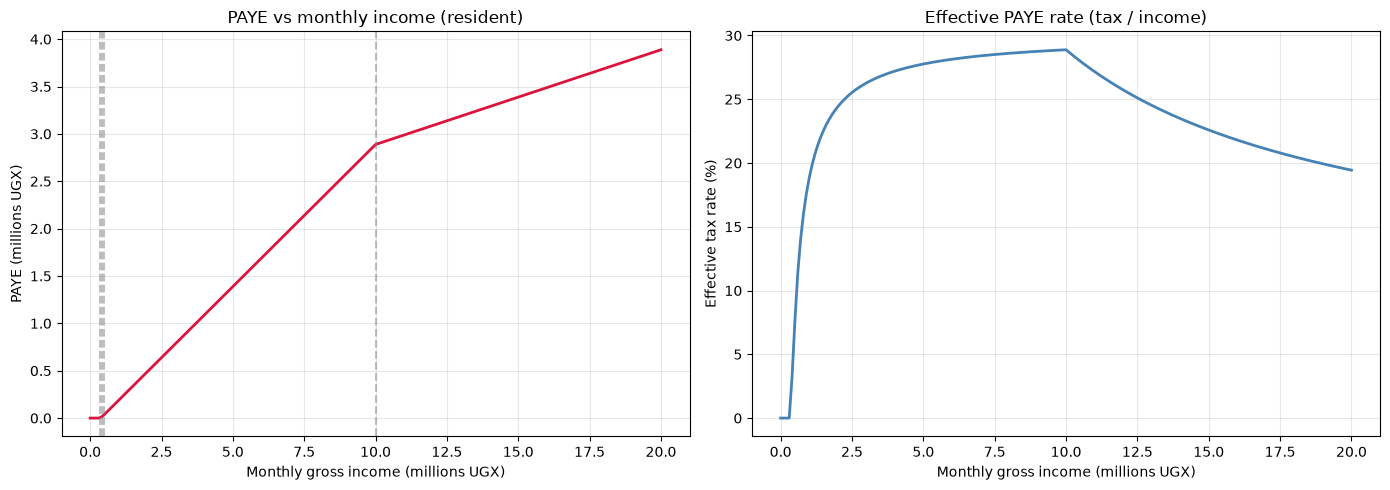

In [6]:
# -------------------------------------------------------------------------
# Effective tax rate across a range of incomes — shows the band structure.
# -------------------------------------------------------------------------
incomes = list(range(0, 20_000_001, 100_000))   # 0 to 20M in 100k steps

records = []
for income in incomes:
    r = paye.calculate(TaxContext(gross=Money(Decimal(income)), as_of=AS_OF))
    records.append({
        "income": income,
        "tax": int(r.tax.amount),
        "net": income - int(r.tax.amount),
    })

df_curve = pd.DataFrame(records)
df_curve["effective_rate"] = df_curve["tax"] / df_curve["income"].replace(0, 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: tax vs income
ax1.plot(df_curve["income"] / 1e6, df_curve["tax"] / 1e6,
         color="crimson", linewidth=2)
ax1.set_xlabel("Monthly gross income (millions UGX)")
ax1.set_ylabel("PAYE (millions UGX)")
ax1.set_title("PAYE vs monthly income (resident)")
for x in [0.335, 0.41, 0.485, 10]:
    ax1.axvline(x=x, color="gray", linestyle="--", alpha=0.5)

# Right: effective rate
ax2.plot(df_curve["income"] / 1e6, df_curve["effective_rate"] * 100,
         color="steelblue", linewidth=2)
ax2.set_xlabel("Monthly gross income (millions UGX)")
ax2.set_ylabel("Effective tax rate (%)")
ax2.set_title("Effective PAYE rate (tax / income)")

plt.tight_layout()
plt.show()

In [7]:
# -------------------------------------------------------------------------
# Non-resident schedule: flat 30%.
# -------------------------------------------------------------------------
for income in ["1000000", "5000000", "20000000"]:
    ctx = TaxContext(
        gross=Money(Decimal(income)),
        resident=False,
        as_of=AS_OF,
    )
    print(f"Non-resident gross {int(income):>12,}  →  {paye.calculate(ctx).tax}")

Non-resident gross    1,000,000  →  300,000 UGX
Non-resident gross    5,000,000  →  1,500,000 UGX
Non-resident gross   20,000,000  →  6,000,000 UGX


---

## 3. Payroll pipeline

`PayrollPipeline` composes `LST`, `NSSF`, and `PAYE` in the order URA
practice requires. The order is documented in `src/payroll.py` and pinned
down by tests, but here it is again:

| # | Step | Base | Effect |
|---|---|---|---|
| 1 | **Local Service Tax (LST)** | fixed amount, district-specific | Reduces chargeable income for PAYE |
| 2 | **NSSF employee (5%)** | gross | Reduces net pay |
| 3 | **PAYE** | gross + allowances − LST | Reduces net pay |
| 4 | **Net pay** | gross + allowances − LST − NSSF − PAYE | — |

NSSF **employer** (10% of gross) is not deducted from the employee; it is
an additional cost the employer pays. It appears in the pipeline output
for reporting.

In [8]:
# -------------------------------------------------------------------------
# Full payslip: 1,000,000 UGX gross, 200,000 allowances, 10,000 LST.
# -------------------------------------------------------------------------
pipeline = PayrollPipeline(
    paye=PAYE(),
    nssf=NSSF(),
    lst=LST(Money(Decimal("10000"))),
)

ctx = TaxContext(
    gross=Money(Decimal("1000000")),
    allowances=Money(Decimal("200000")),
    resident=True,
    as_of=AS_OF,
)

result = pipeline.run(ctx)

# Display as a payslip-style DataFrame.
payslip = pd.DataFrame([
    {"Line": "Gross pay",             "Amount (UGX)": int(result.gross.amount)},
    {"Line": "Allowances",            "Amount (UGX)": int(result.allowances.amount)},
    {"Line": "Chargeable income",     "Amount (UGX)": int((result.gross + result.allowances - result.lst).amount)},
    {"Line": "— Local Service Tax",   "Amount (UGX)": -int(result.lst.amount)},
    {"Line": "— NSSF (employee, 5%)", "Amount (UGX)": -int(result.nssf_employee.amount)},
    {"Line": "— PAYE",                "Amount (UGX)": -int(result.paye.amount)},
    {"Line": "Net pay",               "Amount (UGX)": int(result.net.amount)},
])

display(payslip.style.format({"Amount (UGX)": "{:+,}"}))

print()
print("PAYE breakdown:")
for label, m in result.paye_breakdown.items():
    print(f"  {label:>25}  {m}")

print()
print("Employer cost (not deducted from employee):")
print(f"  NSSF employer 10%  = {result.nssf_employer}")

,Line,Amount (UGX)
0,Gross pay,"+1,000,000"
1,Allowances,"+200,000"
2,Chargeable income,"+1,190,000"
3,— Local Service Tax,"-10,000"
4,"— NSSF (employee, 5%)","-50,000"
5,— PAYE,"-245,250"
6,Net pay,"+894,750"



PAYE breakdown:
                band_1_0.00  0 UGX
                band_2_0.20  15,000 UGX
                band_3_0.25  18,750 UGX
                band_4_0.30  211,500 UGX
                  surcharge  0 UGX
                      total  245,250 UGX

Employer cost (not deducted from employee):
  NSSF employer 10%  = 100,000 UGX


---

## 4. VAT — Value Added Tax

VAT is not per-taxpayer. It is computed per **invoice list**, so
`VAT.calculate(ctx)` raises `NotImplementedError` — the real API is
`VAT.compute_invoices(invoices)`. This is a deliberate design choice:
forcing VAT into the `calculate(ctx)` contract would have invented a
per-taxpayer context that doesn't exist for VAT.

Rules implemented (URA standard baseline):

| Supply type | Output VAT |
|---|---|
| **Standard-rated** | 18% of the invoice amount |
| **Zero-rated** | 0% (input VAT is still recoverable) |
| **Exempt** | 0% (input VAT is generally *not* recoverable) |

**Net VAT payable** = output VAT − input VAT.

In [9]:
# -------------------------------------------------------------------------
# VAT: mix of standard, zero-rated, and exempt invoices with input VAT.
# -------------------------------------------------------------------------
invoices = [
    {
        "type": "standard",
        "amount": Money(Decimal("5_000_000")),
        "input_vat": Money(Decimal("400_000")),
    },
    {
        "type": "standard",
        "amount": Money(Decimal("2_000_000")),
        "input_vat": Money(Decimal("180_000")),
    },
    {
        "type": "zero",       # e.g. exported goods
        "amount": Money(Decimal("3_000_000")),
        "input_vat": Money(Decimal("120_000")),
    },
    {
        "type": "exempt",     # e.g. unprocessed agricultural produce
        "amount": Money(Decimal("1_500_000")),
        "input_vat": Money(Decimal("0")),
    },
]

vat_result = VAT.compute_invoices(invoices)

# Manual computation for the walkthrough:
# standard invoices: (5M + 2M) × 18% = 7M × 18% = 1,260,000
# input VAT: 400,000 + 180,000 + 120,000 + 0 = 700,000
# net VAT payable = 1,260,000 - 700,000 = 560,000

print("VAT summary:")
print(f"  Output VAT (from standard-rated supplies): {vat_result['output_vat']}")
print(f"  Input VAT  (recoverable):                  {vat_result['input_vat']}")
print(f"  Net VAT payable:                           {vat_result['net_vat']}")

# Display as a DataFrame for the notebook.
df_vat = pd.DataFrame([
    {"Line": "Output VAT",  "Amount (UGX)": int(vat_result["output_vat"].amount)},
    {"Line": "Input VAT",   "Amount (UGX)": -int(vat_result["input_vat"].amount)},
    {"Line": "Net VAT",     "Amount (UGX)": int(vat_result["net_vat"].amount)},
])
display(df_vat.style.format({"Amount (UGX)": "{:+,}"}))

VAT summary:
  Output VAT (from standard-rated supplies): 1,260,000 UGX
  Input VAT  (recoverable):                  700,000 UGX
  Net VAT payable:                           560,000 UGX


,Line,Amount (UGX)
0,Output VAT,"+1,260,000"
1,Input VAT,"-700,000"
2,Net VAT,"+560,000"


---

## 5. Corporate Income Tax (CIT)

For resident companies, chargeable income is **revenue minus allowable
deductions**, taxed at a flat **30%**. In our design, `CIT` reuses
`TaxContext` with a small semantic shift:

- `gross` → the company's revenue for the period
- `allowances` → allowable deductions

If deductions exceed revenue, `CIT` raises `InvalidIncomeError` rather
than silently producing a negative chargeable income. That kind of silent
failure is exactly what the assignment warns against.

In [10]:
# -------------------------------------------------------------------------
# CIT on two companies: one profitable, one not.
# -------------------------------------------------------------------------
cit = CIT()

# Company A: revenue 500M, deductions 300M, chargeable 200M
ctx_a = TaxContext(
    gross=Money(Decimal("500_000_000")),
    allowances=Money(Decimal("300_000_000")),
    as_of=AS_OF,
)
result_a = cit.calculate(ctx_a)

# Company B: revenue 100M, deductions 150M — losses, should raise
ctx_b = TaxContext(
    gross=Money(Decimal("100_000_000")),
    allowances=Money(Decimal("150_000_000")),
    as_of=AS_OF,
)

rows = [
    {
        "Company": "A (profitable)",
        "Revenue (UGX)": int(ctx_a.gross.amount),
        "Deductions (UGX)": int(ctx_a.allowances.amount),
        "Chargeable (UGX)": int(result_a.breakdown["chargeable"].amount),
        "CIT @ 30% (UGX)": int(result_a.tax.amount),
    },
]

try:
    cit.calculate(ctx_b)
    rows.append({
        "Company": "B (loss-making)",
        "Revenue (UGX)": int(ctx_b.gross.amount),
        "Deductions (UGX)": int(ctx_b.allowances.amount),
        "Chargeable (UGX)": None,
        "CIT @ 30% (UGX)": None,
    })
    note = "No exception — unexpected!"
except InvalidIncomeError as e:
    rows.append({
        "Company": "B (loss-making)",
        "Revenue (UGX)": int(ctx_b.gross.amount),
        "Deductions (UGX)": int(ctx_b.allowances.amount),
        "Chargeable (UGX)": None,
        "CIT @ 30% (UGX)": None,
    })
    note = f"Correctly raised InvalidIncomeError: {e}"

display(pd.DataFrame(rows).style.format({
    "Revenue (UGX)": "{:,}",
    "Deductions (UGX)": "{:,}",
    "Chargeable (UGX)": "{:,}",
    "CIT @ 30% (UGX)": "{:,}",
}, na_rep="—"))

print()
print(note)

,Company,Revenue (UGX),Deductions (UGX),Chargeable (UGX),CIT @ 30% (UGX)
0,A (profitable),"500,000,000","300,000,000","200,000,000.0","60,000,000.0"
1,B (loss-making),"100,000,000","150,000,000",—,—



Correctly raised InvalidIncomeError: deductions exceed revenue: -50,000,000 UGX


---

## 6. Testing summary

The tax engine is verified by **73 tests** across three files, all running
offline in under a second:

| File | Tests | Covers |
|---|---:|---|
| `tests/test_money.py` | 25 | Rounding, arithmetic, currency checks, comparison, display, immutability |
| `tests/test_taxes.py` | 35 | Boundary values, error handling, property tests, pipeline, VAT, CIT |
| `tests/test_weather_parsing.py` | 13 | *(from Mini-Project 1)* |

### Boundary coverage (as required by the assignment)

Every band edge is tested at the exact shilling:

| Value | Expected PAYE |
|---:|---:|
| 335,000 | 0 |
| 335,001 | 0 |
| 410,000 | 15,000 |
| 410,001 | 15,000 |
| 485,000 | 33,750 |
| 485,001 | 33,750 |
| 10,000,000 | 2,888,250 |
| 10,000,001 | 2,888,250 |

### Property-based tests (Hypothesis)

Three invariants are checked across 200 randomly-generated incomes each:

1. **Non-negative:** `PAYE(income) >= 0` for all `income >= 0`.
2. **Monotonic:** if `a <= b` then `PAYE(a) <= PAYE(b)`.
3. **Never exceeds income:** `PAYE(income) <= income`.

### Running them

```bash
pytest -q
# 73 passed in 0.73s

---

## 7. Discussion Q1 — Why is `float` unsafe for tax computation?

Because IEEE-754 floating point numbers are **binary** fractions, they
cannot represent most decimal fractions exactly. `0.1`, `0.2`, and every
other decimal whose denominator is not a power of two is stored as the
closest representable binary approximation. The error per operation is
tiny (on the order of `10^-17`), but:

1. **Errors accumulate.** A progressive tax involves many multiplications
   and additions. Every operation can introduce a tiny rounding error;
   these compose over the course of a single calculation and compound
   further across periods.
2. **Comparisons become unreliable.** Two paths that should produce the
   same value can differ by `1e-16` and compare unequal. This breaks
   `<`, `==`, and thresholds — exactly what a band-based tax needs.
3. **Rounding becomes non-deterministic.** Whether a computed value
   rounds up or down can flip based on a single-ULP difference deep in
   the multiplication chain.

### A concrete failing example

Run this in Python:

```python
>>> 0.1 + 0.2
0.30000000000000004

>>> 0.1 + 0.2 == 0.3
False

>>> (0.1 + 0.2) * 1000000
300000.00000000006

---

## 8. Discussion Q2 — Where is inheritance justified, and where avoided?

### Inheritance **is** justified: the `Tax` abstract base class

`PAYE`, `NSSF`, `LST`, `VAT`, and `CIT` all share one contract:
given a `TaxContext`, produce a `TaxResult`. That contract is exactly the
shape of an abstract base class:

```python
class Tax(ABC):
    @abstractmethod
    def calculate(self, ctx: TaxContext) -> TaxResult: ...

---

## 9. Extension — `TaxPlanner`: salary vs. dividend

The assignment's extension task offers two options. We implement **Option B**:
a `TaxPlanner` that compares two remuneration scenarios and reports the
after-tax difference.

### Why this is interesting

A business owner in Uganda typically has two ways to extract value from a
company:

1. **Salary** — paid monthly, subject to PAYE and NSSF.
2. **Dividend** — paid from post-CIT profits, subject to withholding tax.

Each has a different tax footprint. `TaxPlanner` runs both paths and
reports the difference so the owner can see the tax consequence of each
choice.

### Design

`TaxPlanner` **composes** `PAYE` and `CIT` rather than inheriting from
either. It doesn't "calculate a tax" — it orchestrates two tax
calculations and compares them. That's a `has-a` relationship, not an
`is-a` relationship. This is the same composition principle we applied to
`PayrollPipeline`.

In [11]:
# Re-import after editing src/taxes.py.
from src.taxes import TaxPlanner, ScenarioResult
print("TaxPlanner ready")

TaxPlanner ready


---

## 10. References

### Tax rules

- **Uganda Revenue Authority**, PAYE schedule for resident individuals
  (monthly). The bands implemented in `src/taxes.py` are those given in
  the Assignment 2 brief; production use requires citing the specific URA
  notice and its effective date.
- **Uganda Revenue Authority**, non-resident PAYE schedule.
  Implemented as a flat 30% for the purposes of this notebook; verify
  against the current published rates before production use.
- **NSSF Act**, employee 5% / employer 10% contributions.
- **Local Service Tax**: modelled as a configurable fixed amount, since
  rates vary by district and by income bracket.

### Programming references

- **Python `decimal` module** — `ROUND_HALF_UP` semantics.
- **`hypothesis`** — property-based testing for Python.
- **PEP 484 / PEP 604** — type hints used throughout `src/`.
- **PEP 557** — data classes for `TaxContext`, `TaxResult`, `Money`,
  `Band`, `BandSchedule`, `PayrollResult`, and `ScenarioResult`.

### Design references

- **Fowler, M.** *Patterns of Enterprise Application Architecture* —
  Money as a value object, Domain Model, and the "separate inputs from
  computations" pattern used in `TaxContext` / `TaxResult`.
- **Evans, E.** *Domain-Driven Design* — the "Ubiquitous Language" concept:
  class names (`PAYE`, `NSSF`, `LST`, `VAT`, `CIT`) match the tax
  terminology used by practitioners.

In [12]:
# Re-import after editing src/taxes.py.
from src.taxes import TaxPlanner, ScenarioResult
print("TaxPlanner ready")

TaxPlanner ready


In [13]:
# -------------------------------------------------------------------------
# Compare: owner extracts 20,000,000 UGX per year, company earns 60,000,000.
# -------------------------------------------------------------------------
planner = TaxPlanner(paye=PAYE(), cit=CIT())

company_profit = Money(Decimal("60_000_000"))
amount = Money(Decimal("20_000_000"))

comparison = planner.compare(company_profit, amount, as_of=AS_OF)

salary = comparison["salary"]
dividend = comparison["dividend"]
difference = comparison["difference"]

print(salary)
print()
print(dividend)
print()
print(f"Difference (salary.net - dividend.net): {difference}")
print()
if difference.amount > 0:
    print("→ Salary leaves the owner with MORE cash.")
elif difference.amount < 0:
    print("→ Dividend leaves the owner with MORE cash.")
else:
    print("→ The two scenarios are equivalent on a net-cash basis.")

df_plan = pd.DataFrame([
    {
        "Scenario": s.label,
        "Gross (UGX)": int(s.gross.amount),
        "CIT (UGX)": int(s.cit.amount),
        "PAYE (UGX)": int(s.paye.amount),
        "WHT (UGX)": int(s.withholding.amount),
        "Net to owner (UGX)": int(s.net.amount),
    }
    for s in (salary, dividend)
])
display(df_plan.style.format({
    "Gross (UGX)": "{:,}",
    "CIT (UGX)": "{:,}",
    "PAYE (UGX)": "{:,}",
    "WHT (UGX)": "{:,}",
    "Net to owner (UGX)": "{:,}",
}))

Salary:
  gross       = 20,000,000 UGX
  CIT         = 18,000,000 UGX
  PAYE        = 3,888,250 UGX
  withholding = 0 UGX
  net         = 16,111,750 UGX

Dividend:
  gross       = 20,000,000 UGX
  CIT         = 18,000,000 UGX
  PAYE        = 0 UGX
  withholding = 2,000,000 UGX
  net         = 18,000,000 UGX

Difference (salary.net - dividend.net): -1,888,250 UGX

→ Dividend leaves the owner with MORE cash.


,Scenario,Gross (UGX),CIT (UGX),PAYE (UGX),WHT (UGX),Net to owner (UGX)
0,Salary,"20,000,000","18,000,000","3,888,250",0,"16,111,750"
1,Dividend,"20,000,000","18,000,000",0,"2,000,000","18,000,000"
